# Checking against known truth

An archived product can tell you whether a port reproduces the original program. It cannot
tell you whether that program measures the right thing, because nobody knows the true
droplets in a real cloud. A synthetic flight does know them.

`arrayprobe.tools.synthetic_truth` draws droplets, and shattering fragments if asked, with
known sizes, positions and times. It renders each one's diffraction image with a Korolev
(2007) optical model and writes a 2D-S raw file. `scripts/truth_harness.py` runs that file
through the engines exactly as a user would, then compares each engine's size distribution
with the truth, size band by size band. For the v3.1.4 chain (run only where that engine is installed; it is not part of this package) it also names the gate that
removed each lost droplet.

This is a check on the method, not on the port: every engine here reproduces its original
program, and the gaps below belong to those programs and to the probe's optics.

**Before this:** [01_validate_against_a_product](01_validate_against_a_product.ipynb) (Validating against a product). **Next:** [03_preregistered_test](03_preregistered_test.ipynb). **Needs:** `pip install "arrayprobe[extra]"` (matplotlib).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/3_validation/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import sys
import tempfile

import numpy as np

from arrayprobe.tools import synthetic_truth as st

sys.path.insert(0, "scripts")
import truth_harness as th  # noqa: E402

## The flight

Eight seconds of droplets from a lognormal distribution (median 60 um), spread through the
whole depth of field and across the array edges, at 130 m/s, with shattering bursts: a
large droplet breaking on the probe tips into a quick run of small fragments. The fragments
are in the manifest but are not part of the true population, so a chain should reject them.

In [3]:
tmp = tempfile.TemporaryDirectory()
root = Path(tmp.name)
FLIGHT = st.FlightSpec(n_seconds=8, rate_per_s=400.0, seed=11, burst_rate_per_s=2.0)
raw, manifest = th.build(root / "flight", FLIGHT)
kind = manifest.array("kind")
imaged = manifest.array("imaged")
print(f"droplets drawn {np.sum(kind == 'droplet')}, imaged {np.sum(imaged & (kind == 'droplet'))}; "
      f"fragments {np.sum(kind == 'fragment')}")
print("size bands (um):", th.BANDS_UM)

droplets drawn 3153, imaged 747; fragments 164
size bands (um): (15, 55, 105, 205, 305, 505, 805)


## Three chains on the same bytes

`v35_stock` is the default engine under stock thresholds. `soda2_water` is SODA-2 with a
real 2D-S probe configuration and `water=1`, SODA-2's Korolev size correction for liquid
droplets, the right setting for this flight. `v314_stock` is v3.1.4 under stock thresholds,
run here, where that engine is present, because the gate attribution below reads its stages.

In [4]:
rows = {}
CHAINS = ("v35_stock", "soda2_water")
for name in CHAINS:
    paths = th.run_chain(name, raw, root / name, FLIGHT)
    rows[name] = (paths, th.compare(name, paths, manifest))

labels = [f"{a}-{b}" for a, b in zip(th.BANDS_UM[:-1], th.BANDS_UM[1:])]
print(f"{'recovered / true concentration':32s}" + "".join(f"{b:>10s}" for b in labels))
for name, (_, row) in rows.items():
    print(f"{name:32s}" + "".join(f"{r:10.2f}" for r in row["conc_ratio_bands"]))
for name, (_, row) in rows.items():
    print(f"{name}: 15-805 um total {row['total_conc_ratio_15_805']:.3f} of the truth")

recovered / true concentration       15-55    55-105   105-205   205-305   305-505   505-805
v35_stock                             1.69      1.09      1.06      0.93      3.01       nan
soda2_water                           0.59      0.67      0.92      1.11      1.25       nan
v35_stock: 15-805 um total 1.343 of the truth
soda2_water: 15-805 um total 0.683 of the truth


Each band's ratio carries the counting uncertainty of its recovered count (the Garwood 95 %
interval). The figure shows it as error bars.

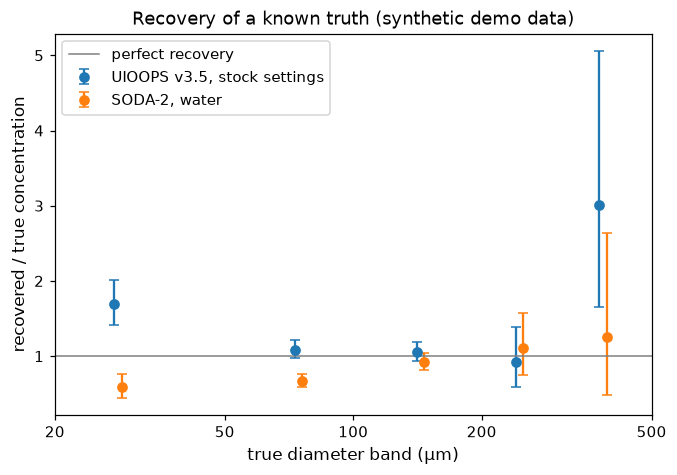

In [6]:
import matplotlib.pyplot as plt  # noqa: E402

mid = np.sqrt(np.array(th.BANDS_UM[:-1]) * np.array(th.BANDS_UM[1:]))
PLAIN = {"v35_stock": "UIOOPS v3.5, stock settings", "soda2_water": "SODA-2, water",
         "v314_stock": "UIOOPS v3.1.4, stock settings"}
fig, ax = plt.subplots(figsize=(7, 4.5))
for k, (name, (_, row)) in enumerate(rows.items()):
    r = np.array(row["conc_ratio_bands"])
    lo, hi = np.array(row["conc_ratio_bands_lo"]), np.array(row["conc_ratio_bands_hi"])
    x = mid * (1 + 0.04 * (k - 1))
    ax.errorbar(x, r, yerr=[r - lo, hi - r], fmt="o", capsize=3, label=PLAIN[name])
ax.axhline(1.0, color="0.5", lw=1, label="perfect recovery")
ax.set(xscale="log", xlabel="true diameter band (µm)", ylabel="recovered / true concentration",
       title="Recovery of a known truth (synthetic demo data)")
ax.set_xticks([20, 50, 100, 200, 500], labels=["20", "50", "100", "200", "500"])
ax.minorticks_off()
ax.legend(fontsize=10)
plt.show()

*Figure 1. Recovered over true concentration in each band of true diameter, for each processing chain run on the same synthetic flight; error bars are the 95 % counting interval and the grey line marks perfect recovery.*

## Reading it

- **Fragments.** No UIOOPS chain is given an inter-arrival threshold file, and without
  one the size-distribution stage skips its shattering test. So every fragment the flight
  drew is accepted and counted as a droplet, and being
  small they inflate the 15-55 um band of every UIOOPS chain.
- **Out-of-focus sizing.** Droplets away from the object plane image larger than they are,
  so the accepted droplets land several bins above their true size
  and move up a band. SODA-2's `water=1` applies a size correction for exactly this.
- **Framing rejections.** Most lost droplets are rejected at the framing stage
  (`imgproc`), before the size-distribution gates see them.
- **Few large droplets.** The top bands hold a handful of particles, so their ratios carry
  wide intervals; the empty 505-805 um band has no ratio.

The harness runs more chains and flights from the command line:
`python scripts/truth_harness.py --help`.